## COMP5712M: Programming for Data Science 

## Group project: Data Analysis Project


# _Project Title_ - please name your project


_Give names and emails of group members here:_

* Shiyu Zong, hvbh0937@leeds.ac.uk

# Project Plan

## The Data (10 marks)

_Here you should describe the data including details of:
where it comes from, what data it contains, is it accurate. (Potentially you could create data from a simulation but you should still explain why and how you intend to generate this data.)_

_It can be just one dataset or several that can be combined
logically. To ensure sufficient depth for analysis, the final dataset must contain a mininum of 1000 rows and 7 features._

_There are 10 marks for this, so a fairly detailed description
of the data is expected. You should include details including the size, the features, range of values, and so on._



## Project Aim and Objectives (5 marks)

_Here you should describe the general aim of your project in
around 200-300 words._

_This can can be anything from classifying items according to
their characteristic features (which mushrooms are poisonous?) 
to simulating an evolving process (will the rabbits eat all
the carrots or get eaten by the foxes?)_

_Here some ideas of general types of processing functionality
that you could implement:_

* _Classification: separate data items into classes according
  to their charactersitics (can be either a definite or a
  statistical kind of classification)_
* _Corellation: find correspondences between different attributes within
  a dataset_
* _Search: find solutions matching some criteria_
* _Visualisation: find informative ways to
  display the structure of a large and/or complex dataset useful for decision making_
* _Query Answering: create a system that enables one to retrieve information by evaluating some form of query representation_
* _Simulation: model the evolution of a complex process_

### Specific Objective(s)

_You should chose and list __up to 4__ specific objectives suited to the data you will be working with and the type of project you wish to carry out according to the project aim. 
There should be <b>at least one
per person doing the project</b>. There is no need
for  the objectives them to be completely different. 
They could be different
stages of the processing requirements, or different processing
functions that the system  provides. Or just
different aspects of data analysis that will be conducted.
Typically, it is expected that there would be one objective
per person. Replace the following examples with your own objectives:_

* __Objective 1:__ _create a Python datastructure that will ensure world peace_
* __Objective 2:__ _stop global warming using a pandas dataframe_
* __Objective 3:__ _end poverty using matplotlib_
* __Objective 4:__ _Future Adoption and Resistance_

## System Design (5 marks)

_Describe your code in terms of the
following two sections._

### Architecture

_Typically this would be  a pipeline in which __data__ goes through several
stages of transformation and analysis, but other architectures are possible.
This does not need to be particularly complicated. A simple diagram with
100-150 words of explanation would
be a good way to present your architecture._
  
### Processing Modules and Algorithms

_Briefly list and describe the most significant computational components of your system and the algorithms you will use to implement them. 
This could include things like:_

* _cleaning the data by removing outliers_
* _combining different datasets_
* _converting samples to a special representation (such as feature vectors)_
* _constructing a special data-structure (such as a decision tree)_
* _running some kind of analysis_

_Your list can be presented in similar form to the one just given, 
but should include a brief
but more specific description of the components and/or algorithms.
Probably three or four components is sufficient for most projects, but
you may want to have more._



# Program Code (15 marks)


Please note the following about your code:
* <b><i>You may import any packages/modules you wish to use for your project.</i></b> However, for special packages/modules, it would be nice to put comments or a sentence on where these modules are used in the project.


* <b><i>You should submit your notebook in a state where all cells have been
    executed and are displaying the output that you wish to present for grading.</i></b>
    (We will not normally run your code, unless for some reason we wish to check
    that the code functionality matches the given description.)
    
    
* It is strongly suggested you use __function definitions to organise your code__. As well as being generally good programming practice, it will be helpful for easy and flexibily presentation of results visualisations later in the document. In the visualisation sections you will be able to produce images in a concise and flexible way by calling functions defined in the program code secion.

## Shared raw data import and validation

<!-- 填写说明：解释原始数据入库、已有数据库复用及完整性检查；schema 是字段说明，不是受访者数据。 -->

In [18]:
# 共同入库：先导入标准库，再导入 pandas。pd 是 pandas 的常用简称。
# closing 配合 with 使用，可以在代码结束或发生错误时关闭数据库连接。
from contextlib import closing
from pathlib import Path
import sqlite3
import tempfile
import pandas as pd

# Path.cwd() 是当前工作目录，不一定是 Notebook 所在目录。
# 此处兼容从数据文件所在目录或项目根目录运行；更换目录结构时需要调整下面的路径。
data_dir = Path.cwd()
if not (data_dir / 'survey_results_public.csv').is_file():
    data_dir = data_dir / 'docs' / 'member_d'

# dtype=str 按文本读取；keep_default_na=False 保留空字符串和字面值 NA。
# 这里保存原始值，缺失值的解释留给后续分析；不要为了方便在原表阶段直接填补。
responses_df = pd.read_csv(data_dir / 'survey_results_public.csv', dtype=str, keep_default_na=False)
columns_meta_df = pd.read_csv(data_dir / 'survey_results_schema.csv', dtype=str, keep_default_na=False)
# duplicated 检查字段说明中是否有重复名称；set 比较两个文件的字段集合。
# 如果不一致，用 raise 明确停止，避免在字段含义不可靠时继续分析。
if columns_meta_df['column'].duplicated().any() or set(responses_df.columns) != set(columns_meta_df['column']):
    raise ValueError('Inconsistency between survey data fields and their descriptions')
# resolve() 得到绝对路径；下方和成员 D 的查询都使用同一个 db_path。
db_path = (data_dir / 'survey.db').resolve()

# 定义可重复使用的检查函数：比较数据库与两个原始 DataFrame，而不是修改数据库。
def validate_database(path):
    # SQLite 的 mode=ro 只读打开现有数据库；URI 格式由 as_uri() 生成。
    with closing(sqlite3.connect(path.as_uri() + '?mode=ro', uri=True)) as conn:
        # 分别检查回答表和字段说明表；循环中的 table 是表名，source 是对应的 CSV 数据。
        for table, source in [('responses', responses_df), ('columns_meta', columns_meta_df)]:
            # PRAGMA 查询列结构；COUNT(*) 查询行数。fetchall/fetchone 取回 SQL 结果。
            structure = conn.execute(f'PRAGMA table_info("{table}")').fetchall()
            columns = [row[1] for row in structure]
            count = conn.execute(f'SELECT COUNT(*) FROM "{table}"').fetchone()[0]
            if columns != source.columns.tolist() or count != len(source):
                raise ValueError(f'Inconsistency between {table} rows or fields and the CSV')
            # 行数与列顺序一致后，按 rowid 顺序逐行比较所有值，不只检查前几行。
            # zip 将数据库行与 DataFrame 行配对；any 在发现第一处差异时返回 True。
            rows = conn.execute(f'SELECT * FROM "{table}" ORDER BY rowid')
            if any(row != original for row, original in zip(rows, source.itertuples(index=False, name=None))):
                raise ValueError(f'Inconsistency between {table} data and the CSV')
            print(f'{table}: {count:,} rows, {len(columns)} columns; column types: {sorted({row[2] for row in structure})}')
            print('Fields:', ', '.join(columns[:10]), '...' if len(columns) > 10 else '')
        # 受访者 ID 必须非空且唯一，否则后续按人统计会产生错误。
        # COUNT(DISTINCT ...) 统计不同 ID 的数量；SQL 条件同时检查空值和原始缺失文本。
        missing_ids = conn.execute("SELECT COUNT(*) FROM responses WHERE ResponseId IS NULL OR ResponseId IN ('', 'NA')").fetchone()[0]
        duplicate_ids = conn.execute('SELECT COUNT(*) - COUNT(DISTINCT ResponseId) FROM responses').fetchone()[0]
        print(f'Missing ResponseId values: {missing_ids}; duplicates: {duplicate_ids}')
        if missing_ids or duplicate_ids:
            raise ValueError('Missing or duplicate ResponseId values; please check the source data')

# 数据库已存在时只验证和复用，不覆盖；验证失败应先检查来源，而不是强行跳过。
if db_path.exists():
    validate_database(db_path)
    print('The existing database matches the source CSV; the tables were not overwritten.')
else:
    # 数据库不存在时先建临时目录和临时数据库；离开 with 后临时目录会被清理。
    # 只有临时数据库完整通过验证后才创建目标文件，避免留下不完整的 survey.db。
    with tempfile.TemporaryDirectory(dir=data_dir) as temp_dir:
        temp_db = Path(temp_dir).resolve() / 'survey.db'
        with closing(sqlite3.connect(temp_db)) as conn:
            # to_sql 写入两张表；if_exists='fail' 防止覆盖同名表，index=False 不写入索引列。
            responses_df.to_sql('responses', conn, if_exists='fail', index=False)
            columns_meta_df.to_sql('columns_meta', conn, if_exists='fail', index=False)
        validate_database(temp_db)
        # hardlink_to 为已验证的数据库创建目标路径；如果目标已存在，会报错而非覆盖。
        db_path.hardlink_to(temp_db)
    print(f'Source data validated and imported: {db_path}')

responses: 30,903 rows, 212 columns; column types: ['TEXT']
Fields: ResponseId, Age, CodeMain, Education, Employment, EmploymentAddl, ICorPM, WorkSetting, LearnCode, LearnCodeHow ...
columns_meta: 212 rows, 10 columns; column types: ['TEXT']
Fields: column, qid, qname, question, type, sub, sq_id, source_columns, transformation, nonmissing 
Missing ResponseId values: 0; duplicates: 0
The existing database matches the source CSV; the tables were not overwritten.


## Member D: Objective 4 - Future Adoption and Resistance

#### Step 1: Query the database

For Objective 4, we read the respondent identifier, `AISelect` and the five `AIWork` fields from the shared database. The fields describe current use, expected increases and decreases, no planned use, and tasks outside the respondent's workflow. We also retrieve their question descriptions to check what the responses mean. The database is opened in read-only mode.

In [19]:
# 步骤 1：从共同数据库读取成员 D 需要的列和字段说明。
# db_path 来自上面的共享入库步骤；mode=ro 表示只读，不会创建或修改数据库。
# 先运行共同入库单元格；closing 确保查询结束后关闭连接。
with closing(sqlite3.connect(db_path.as_uri() + '?mode=ro', uri=True)) as conn:
    # SQL 的 SELECT 选择列、FROM 选择表；read_sql_query 将结果转成 DataFrame。
    # 当前没有 WHERE 筛选受访者；若以后改变研究范围，要先与全组统一口径。
    work_df = pd.read_sql_query('''
        SELECT ResponseId, AISelect, AIWorkCurrentlyUse, AIWorkExpectMore,
               AIWorkExpectLess, AIWorkDoNotPlanToUse, AIWorkNotInWorkflow
        FROM responses
    ''', conn)
    # 元数据的 WHERE ... IN (...) 只取这六个字段的说明；双引号用于引用列名。
    # 如需增加分析字段，需同时检查响应表查询、元数据查询和后续处理是否一致。
    work_schema = pd.read_sql_query('''
        SELECT "column", question, sub, source_columns, transformation
        FROM columns_meta
        WHERE "column" IN ('AISelect', 'AIWorkCurrentlyUse', 'AIWorkExpectMore',
                           'AIWorkExpectLess', 'AIWorkDoNotPlanToUse', 'AIWorkNotInWorkflow')
    ''', conn)

# f 字符串中的 :, 给数字加千位分隔符；display 在 Notebook 中显示表格。
print(f'read {len(work_df):,} respondents and {len(work_df.columns)} fields.')
display(work_schema[['column', 'sub', 'question']])

read 30,903 respondents and 7 fields.


,column,sub,question
0,AISelect,NA,Do you currently use AI tools or AI agents in ...
1,AIWorkCurrentlyUse,Currently use AI or AI agents for this,Which parts of your workflow are you currently...
2,AIWorkExpectMore,Expect to use AI More or AI agents more for this,Which parts of your workflow are you currently...
3,AIWorkExpectLess,Expect to use AI or AI agents less for this,Which parts of your workflow are you currently...
4,AIWorkDoNotPlanToUse,Do not use AI or AI agents for this and do not...,Which parts of your workflow are you currently...
5,AIWorkNotInWorkflow,This is not part of my workflow,Which parts of your workflow are you currently...


The query returns 30,903 respondents and seven fields. The question asks about current AI use in each task and expected changes over the next year. The analysis retains all respondents at this stage; eligibility is assessed separately for each task in Step 4.


#### Step 2: Population and missing values

We make an analysis copy and treat empty strings and `NA` as missing in the selected fields. Missing values may reflect skipped or unanswered questions and are not treated as a negative response. We count recorded answers and check whether respondents with `AIWork` records also selected a tool associated with the question's display condition. This check does not remove respondents.

In [20]:
# 步骤 2：只在分析副本中识别缺失，不修改数据库原表。
# 列表集中保存五个矩阵字段名，后面多处复用；修改字段时要同步检查统计逻辑。
work_columns = ['AIWorkCurrentlyUse', 'AIWorkExpectMore', 'AIWorkExpectLess',
                'AIWorkDoNotPlanToUse', 'AIWorkNotInWorkflow']
# copy() 建立独立副本；replace 只替换指定列中的两种原始缺失写法为 pandas 的缺失值。
# 这里没有把缺失当作“否”，也没有改变数据库中的原始数据。
work_clean = work_df.copy()
work_clean[['AISelect'] + work_columns] = work_clean[['AISelect'] + work_columns].replace(
    {'': pd.NA, 'NA': pd.NA}
)
# notna() 判断是否有记录；any(axis=1) 按行判断五列是否至少一列有记录。
# 布尔值求和会统计 True 的数量；对 DataFrame 直接 sum 则默认按列统计。
has_aiwork = work_clean[work_columns].notna().any(axis=1)
print(f'At least one of the five status fields contains a record:{has_aiwork.sum():,} 人')
display(work_clean[work_columns].notna().sum().rename('有记录人数').to_frame())

# 检查问卷展示条件：选择以下任一种工作 AI 工具的人会看到 AIWork。
# 请以问卷实际展示规则为准维护这个集合；此处只报告异常，不自动删除受访者。
work_ai_tools = {'AI coding assistants or coding agents', 'General-purpose AI chat tools',
                 'AI agents or automated workflows', 'Internal AI tools built by my company'}
# fillna('') 仅用于本次检查；split(';') 按分号拆分所选工具，不会修改 work_clean。
# set(items) & work_ai_tools 取集合交集；bool 判断交集是否非空，apply 逐行执行。
# ~ 表示逐项取反，& 表示逐项且；异常结果需要检查，不能直接断定数据一定错误。
choices = work_clean['AISelect'].fillna('').str.split(';')
shown_aiwork = choices.apply(lambda items: bool(set(items) & work_ai_tools))
print(f'AIWork shown incorrectly: {(has_aiwork & ~shown_aiwork).sum():,} 人; please check anomalies.')

At least one of the five status fields contains a record:12,547 人


,有记录人数
AIWorkCurrentlyUse,11210
AIWorkExpectMore,10189
AIWorkExpectLess,5296
AIWorkDoNotPlanToUse,8338
AIWorkNotInWorkflow,7783


AIWork shown incorrectly: 0 人; please check anomalies.


A total of 12,547 respondents have a record in at least one of the five `AIWork` fields. All of these respondents also match at least one of the checked `AISelect` tool choices. The field counts may overlap because one respondent can have records in several fields.


#### Step 3: Task preparation

Each `AIWork` field can contain several tasks separated by semicolons. We split these values and reshape them into a table with one row per respondent, status and task. Duplicate combinations are removed so that a respondent is counted at most once for the same task and status. Original task names are retained.

In [21]:
# 步骤 3：将分号分隔的任务拆成一人、一状态、一任务一行。
# melt 将五个状态列由宽表转成长表：保留 ID，原列名放入 status，原值放入 task。
aiwork_long_df = work_clean.melt(id_vars='ResponseId', value_vars=work_columns,
                                  var_name='status', value_name='task')
# 先去除缺失任务；split 产生任务列表，explode 把列表中的每个任务展开成单独一行。
# 分隔符是分号；任务名称本身可能包含逗号，不能改用逗号拆分。
aiwork_long_df = aiwork_long_df.dropna(subset=['task'])
aiwork_long_df['task'] = aiwork_long_df['task'].str.split(';')
aiwork_long_df = aiwork_long_df.explode('task')
# strip 去除任务首尾空格，再过滤空字符串；不改动名称内部的标点或文字。
aiwork_long_df['task'] = aiwork_long_df['task'].str.strip()
aiwork_long_df = aiwork_long_df[aiwork_long_df['task'] != '']
# 同一人对同一任务的同一状态最多计一次；其他任务和其他状态仍保留。
aiwork_long_df = aiwork_long_df.drop_duplicates(['ResponseId', 'status', 'task'])
if aiwork_long_df.empty:
    raise ValueError('No AIWork task records available for analysis; please check the data.')
# nunique 统计不同任务数，head 默认预览前五行；可改用 head(10) 查看更多记录。
print(f'Identified {aiwork_long_df["task"].nunique()} tasks; please verify the original names with member A.')
display(aiwork_long_df.head())

Identified 19 tasks; please verify the original names with member A.


,ResponseId,status,task
0,1,AIWorkCurrentlyUse,Architecture or technical design exploration
3,4,AIWorkCurrentlyUse,"Debugging, troubleshooting, or refactoring code"
3,4,AIWorkCurrentlyUse,Finding or fixing security issues
3,4,AIWorkCurrentlyUse,Generating code in an unfamiliar area
6,7,AIWorkCurrentlyUse,"Debugging, troubleshooting, or refactoring code"


The prepared data contain 19 task categories. The task names and splitting rules should be checked against Member A's analysis before the group results are compared.


#### Step 4: Overlap and denominators

We examine the recorded states for each respondent and task. For now, we exclude a respondent from a task's denominator if the task is marked as outside their workflow, or if its recorded states contain an obvious conflict: both expected increase and decrease, or no use and no planned use alongside current use, expected increase or expected decrease. Current use may coexist with an expected increase or decrease. Exclusion applies only to the affected respondent-task combination.

The provisional denominator `N` is the number of respondents with a recorded, applicable and non-conflicting state for that task. It may include someone whose only recorded state is current use. This rule and the conflict treatment need to be confirmed with Member A.

In [22]:
# 步骤 4：按受访者和任务检查状态，计算暂定分母。
# 每个任务的 N 只包括有该任务记录、未标记不属于工作流程且无明显冲突的人。
# crosstab 以 ID 和任务作为组合索引、状态作为列；gt(0) 将计数变成 True/False。
# reindex 确保五个状态列都存在，即使某个状态在数据中完全没有出现。
task_flags = pd.crosstab(
    [aiwork_long_df['ResponseId'], aiwork_long_df['task']], aiwork_long_df['status']
).reindex(columns=work_columns, fill_value=0).gt(0)
# 为每个布尔状态取简短变量名，方便检查组合条件；每个值对应一个人和一个任务。
current = task_flags['AIWorkCurrentlyUse']
more = task_flags['AIWorkExpectMore']
less = task_flags['AIWorkExpectLess']
no_plan = task_flags['AIWorkDoNotPlanToUse']
not_work = task_flags['AIWorkNotInWorkflow']

# 当前使用可与预计增加或减少同时出现；以下组合暂定为明显冲突。
# & 是“且”，| 是“或”，~ 是“非”；括号使各个条件的组合更加明确。
# 如全组决定采用其他冲突规则，应先核对问卷题意，再修改条件和结果说明。
conflict = (more & less) | (no_plan & (current | more | less))
# 优先记录不属于工作流程的排除，再统计其余记录的冲突，避免重复计算排除人数。
# included 只保留未标记不适用、也没有上述冲突的已记录组合。
task_flags['excluded_not_work'] = not_work
task_flags['excluded_conflict'] = ~not_work & conflict
task_flags['included'] = ~not_work & ~conflict
# groupby(level='task') 按组合索引中的任务汇总；size 计行，sum 统计 True 的个数。
# recorded = 该任务有记录的人数；N = 纳入人数；另两列记录不重复的排除人数。
task_audit = task_flags.groupby(level='task').agg(
    recorded=('included', 'size'), N=('included', 'sum'),
    not_in_workflow=('excluded_not_work', 'sum'), conflict=('excluded_conflict', 'sum')
)
# 无任务记录人数 = 总人数减去该任务有记录人数；无记录不等于选择“不使用”。
task_audit['no_task_record'] = len(work_clean) - task_audit['recorded']
print('N is the number of respondents with analyzable records for the task, which may include those with only current usage records.')
print('The conflict column does not double-count those excluded for not being in the workflow; the criteria should be finally confirmed with member A.')
display(task_audit)

N is the number of respondents with analyzable records for the task, which may include those with only current usage records.
The conflict column does not double-count those excluded for not being in the workflow; the criteria should be finally confirmed with member A.


,recorded,N,not_in_workflow,conflict,no_task_record
task,,,,,
"Analyzing data, logs, metrics, or query results",11576,9959,1502,115,19327
Answering complex or ambiguous technical questions,11742,11090,514,138,19161
Answering straightforward technical questions,11814,11201,500,113,19089
Architecture or technical design exploration,11920,10363,1445,112,18983
Creating or configuring development/test environments,11437,9263,2046,128,19466
"Debugging, troubleshooting, or refactoring code",12036,11602,323,111,18867
"Deploying, operating, or troubleshooting production systems",11382,8746,2507,129,19521
Finding or fixing security issues,11629,9295,2223,111,19274
Generating code in a familiar area,12124,11770,276,78,18779


Across all tasks, 29,537 respondent-task combinations are excluded because the task is marked outside the workflow, and a further 2,063 are excluded for conflicts. These are combinations, not distinct people. The resulting task denominators range from 6,408 to 11,770; the audit table also shows how many respondents have no record for each task.


#### Step 5: Summary statistics

Using the eligible respondent-task records, we count how many respondents selected each of the three future-related states for every task. Each percentage is the state count divided by that task's `N`, multiplied by 100. The table is used to prepare the figures in Project Outcome.

In [23]:
# 步骤 5：统计各任务的状态人数和百分比，绘图留在 Project Outcome。
# 状态可能重叠；没有选择某状态不一定代表明确回答了“否”。
# 选择三个要报告的状态，再用 included 的布尔值筛选每个任务的有效记录。
future_columns = ['AIWorkExpectMore', 'AIWorkExpectLess', 'AIWorkDoNotPlanToUse']
valid_flags = task_flags[task_flags['included']]
# 布尔值求和得到每任务、每状态的选中人数；reindex 保留审核表中的全部任务。
counts = valid_flags.groupby(level='task')[future_columns].sum()
counts = counts.reindex(task_audit.index, fill_value=0)
# 把各任务的 N 放到结果表第一列；pandas 按任务索引对齐，不依赖行的排列顺序。
summary = counts.copy()
summary.insert(0, 'N', task_audit['N'])
# 检查分母和人数，避免除零或输出不合理比例；出现错误时先检查数据和规则。
if (summary['N'] == 0).any():
    raise ValueError('There are tasks with a denominator of 0; please check the filtering results before calculating percentages.')
for column in future_columns:
    if (summary[column] > summary['N']).any():
        raise ValueError(f'The number of respondents for {column} exceeds the task denominator; please check the data.')
    # 每个状态单独除以同一任务的 N；若改成只分析有未来回答的人，必须重新定义分母。
    summary[column + '_pct'] = summary[column] / summary['N'] * 100
# round(2) 仅用于显示两位小数，不改变 summary 中保存的精度。
display(summary.round(2))

status,N,AIWorkExpectMore,AIWorkExpectLess,AIWorkDoNotPlanToUse,AIWorkExpectMore_pct,AIWorkExpectLess_pct,AIWorkDoNotPlanToUse_pct
task,,,,,,,
"Analyzing data, logs, metrics, or query results",9959,4197,572,1779,42.14,5.74,17.86
Answering complex or ambiguous technical questions,11090,3728,1209,1995,33.62,10.90,17.99
Answering straightforward technical questions,11201,3321,781,1851,29.65,6.97,16.53
Architecture or technical design exploration,10363,3253,875,2183,31.39,8.44,21.07
Creating or configuring development/test environments,9263,3157,672,3142,34.08,7.25,33.92
"Debugging, troubleshooting, or refactoring code",11602,4225,887,994,36.42,7.65,8.57
"Deploying, operating, or troubleshooting production systems",8746,2531,731,3927,28.94,8.36,44.90
Finding or fixing security issues,9295,4266,671,1592,45.90,7.22,17.13
Generating code in a familiar area,11770,3705,859,1030,31.48,7.30,8.75


The summary table reports `N`, counts and percentages for expected more use, expected less use, and no use with no plan to use. It uses a task-specific denominator, not the total number of survey respondents. The recorded states are not assumed to be exhaustive or mutually exclusive, so their percentages do not have to add up to 100%.


# Project Outcome (10 + 10 marks)

_This section should describe the outcome of the project by means of both explanation of the results and by graphical visualisation in the form of graphs, charts or or other kinds of diagram_

_The section should begin with a general overview of the results and then have a section for each of the project objectives. For each of these objectives an explanation of more specific results relating to that objective shoud be given, followed by a section presenting some visualisation of the results obtained. (In the case where
the project had just one objective, you should still have a section describing
the results from a general perspective followed by a section that focuses on
the particular objective.)_

_The marks for this section will be divided into 10 marks for Explanation
and 10 marks for Visualisation. These marks will be awarded for the Project Outcome
section as a whole, not for each objective individually. Hence, you do not
have to pay equal attention to each. However, you are expected to have a
some explanation and visualisation for each. It is suggested you have
200-400 words explanation for each objective._

## Overview of Results
_Give a general overview of the results (around 200 words)._

## Objective 4: Future Adoption and Resistance
### Explanation of Results

This objective examines respondents' expected AI use across 19 work tasks over the next year. Of the 30,903 respondents in the dataset, 12,547 have a record in at least one of the five relevant `AIWork` fields. For each task, we calculate percentages among respondents with an applicable, non-conflicting recorded state. The task-specific denominator ranges from 6,408 to 11,770 and can include respondents whose only recorded state is current use. The denominator and conflict rules are provisional and should be confirmed with Member A.

Finding or fixing security issues has the highest proportion expecting more use: 4,266 of 9,295 respondents (45.90%). This is followed by analysing data, logs, metrics or query results (4,197 of 9,959; 42.14%). Expected decreases are less common: the highest proportion is for answering complex or ambiguous technical questions (1,209 of 11,090; 10.90%). These figures show which states were recorded within each task's eligible group, rather than a forecast of actual future behaviour.

The highest proportion reporting that they do not use AI and do not plan to use it is for writing emails, messages, summaries or other communication (5,103 of 10,094; 50.55%). Deploying, operating or troubleshooting production systems follows at 44.90% (3,927 of 8,746). By contrast, the corresponding figure for debugging, troubleshooting or refactoring code is 8.57% (994 of 11,602). These differences suggest that intentions vary by task, but the survey does not establish why respondents made these choices.

The question was shown only under certain conditions, and missing records may have several causes. We do not interpret a missing state as a negative answer. The recorded states may overlap, and the percentages are not intended to sum to 100%. Results reflect self-reported expectations, not proof of future actions, rejection of AI in general, or jobs being replaced.


### Visualisation

**Figure 1: Expected increase and decrease**

The grouped bars compare the percentages expecting more and less AI use for each task over the next year. Tasks are ordered by the percentage expecting more use. The label for each task shows its eligible denominator `N`.

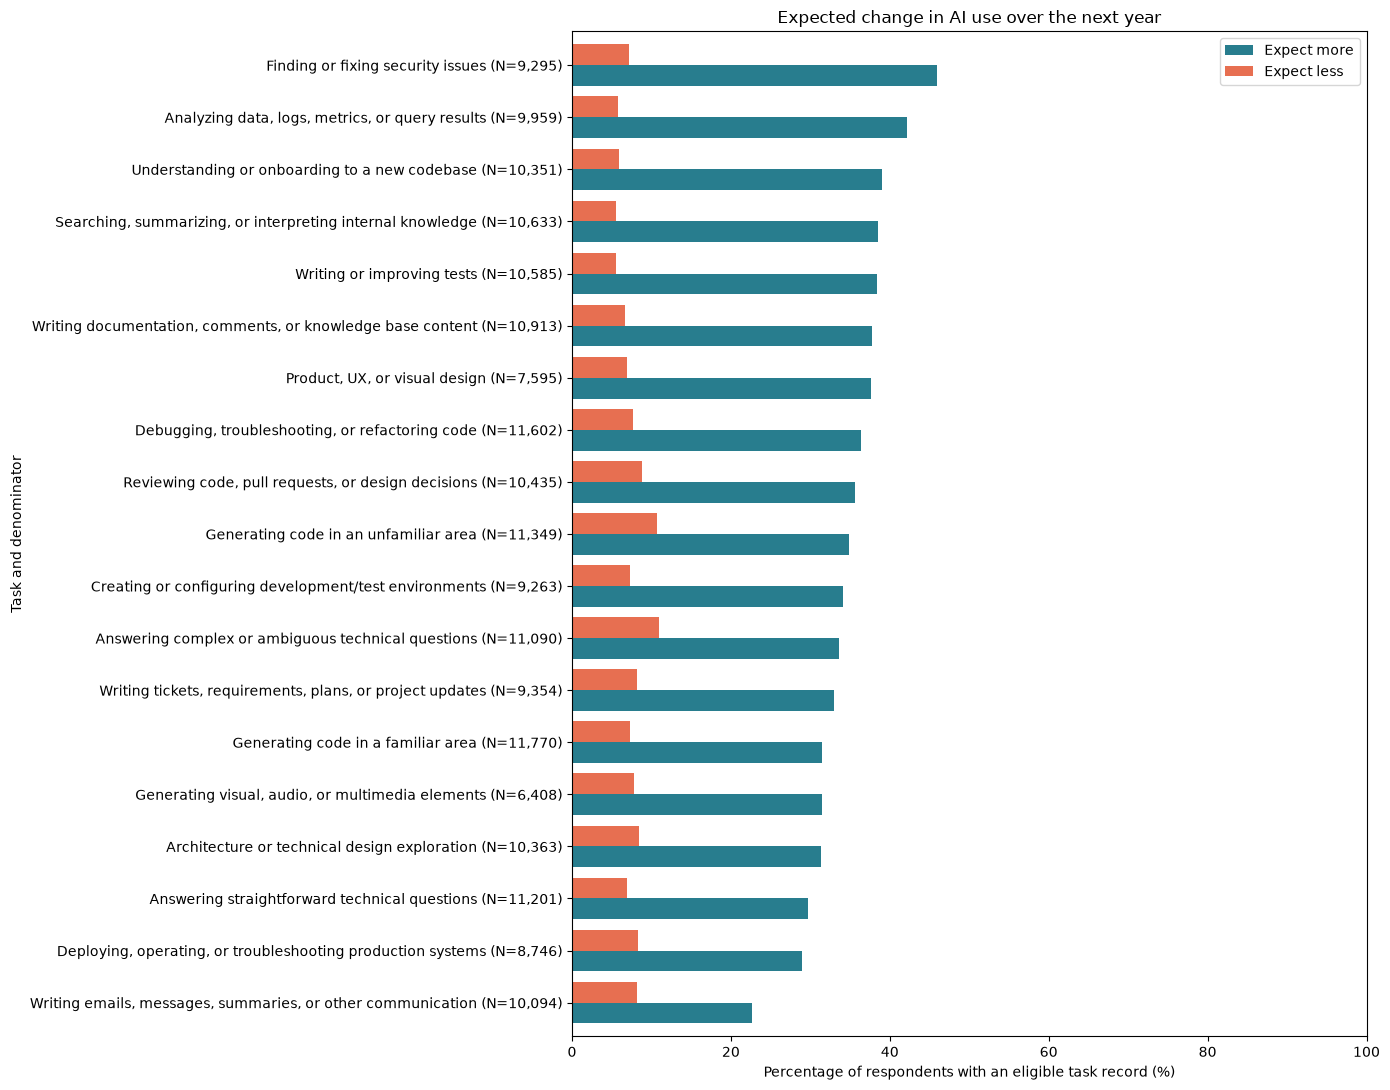

In [24]:
# 图 1：比较每个任务中预计增加和减少使用的选择比例。
# pyplot 提供绘图功能；如果环境缺少 matplotlib，需按项目依赖安装后重启或选择正确内核。
import matplotlib.pyplot as plt

# 按预计增加比例升序排序，横向条形图通常将较大值显示在上方。
# 修改排序列可以改变任务顺序，但应同步修改图前说明；copy 不改变原统计表。
plot_data = summary.sort_values('AIWorkExpectMore_pct').copy()
# zip 将任务名与对应分母配对；列表推导式生成标签，:, 为人数添加千位分隔符。
plot_data.index = [f'{task} (N={n:,})' for task, n in zip(plot_data.index, plot_data['N'])]
# figsize 单位为英寸，可调整画布大小；barh 绘制横向分组条形图。
fig, ax = plt.subplots(figsize=(14, 11))
plot_data[['AIWorkExpectMore_pct', 'AIWorkExpectLess_pct']].plot.barh(
    ax=ax, color=['#287d8e', '#e76f51'], width=0.8
)
# 可修改标题、轴名称、图例和颜色以适配最终报告；两组数据使用相同任务分母。
ax.set_title('Expected change in AI use over the next year')
ax.set_xlabel('Percentage of respondents with an eligible task record (%)')
ax.set_ylabel('Task and denominator')
# 百分比使用 0 到 100 的统一横轴，便于比较；tight_layout 尝试避免文字被裁切。
ax.set_xlim(0, 100)
ax.legend(['Expect more', 'Expect less'])
fig.tight_layout()
plt.show()

**Figure 2: Tasks with no current or planned use**

The bars rank tasks by the percentage of eligible respondents who selected that they do not use AI for the task and do not plan to use it. Each percentage uses the task-specific `N` shown in the label; respondents who marked the task as outside their workflow are excluded.

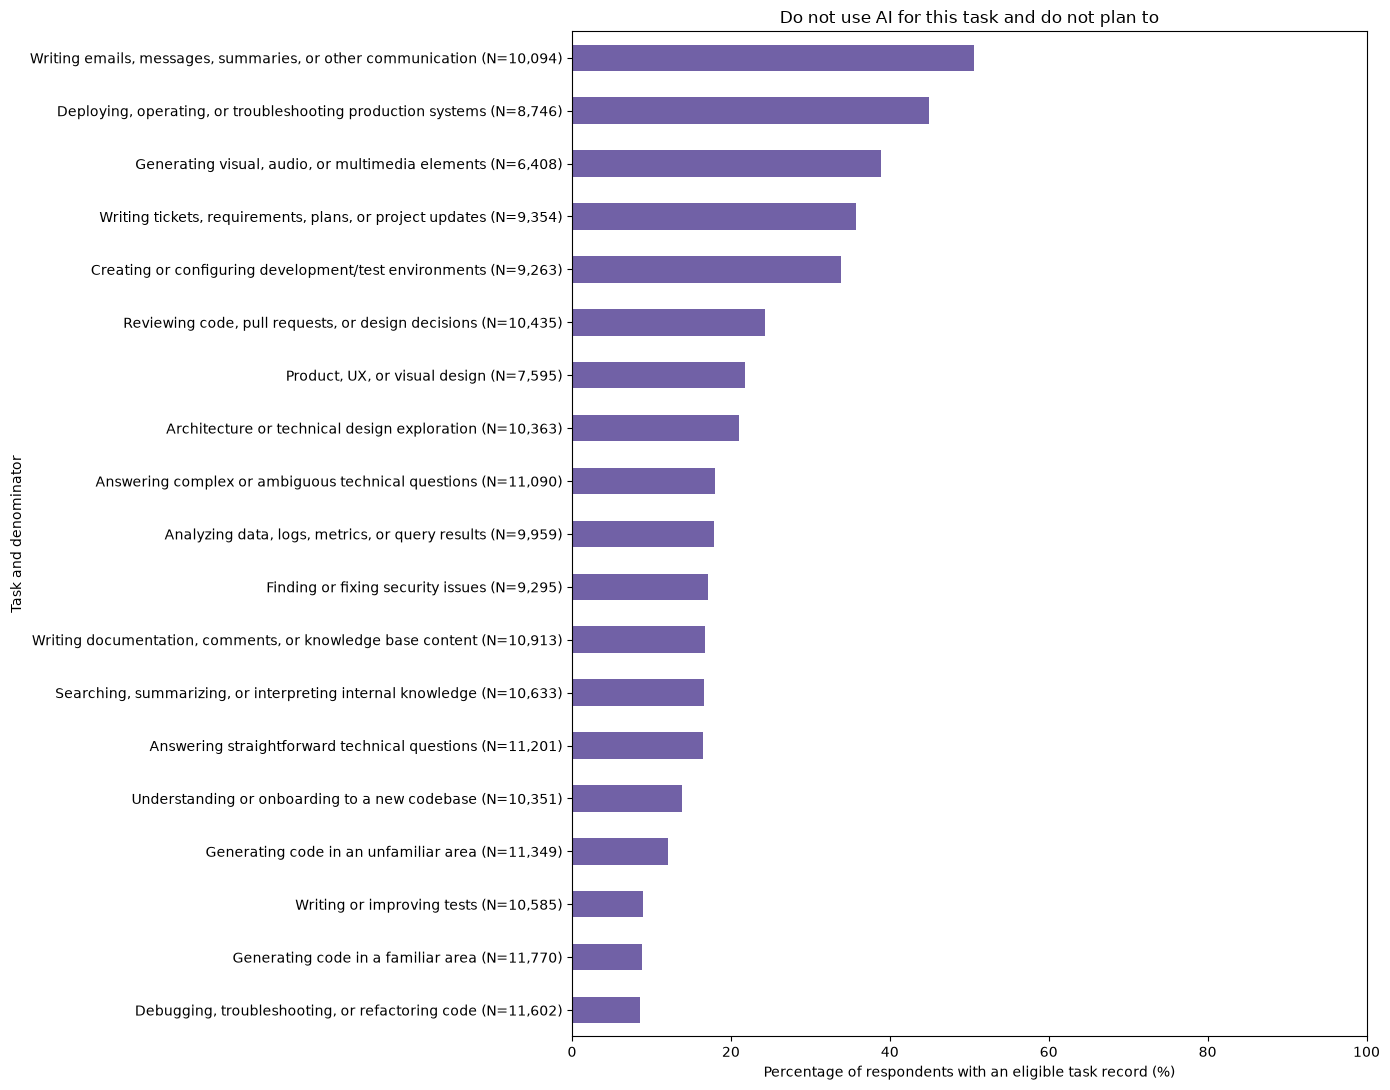

In [25]:
# 图 2：展示不使用且不计划使用 AI 的任务选择比例。
# 这里重新按该状态的百分比排序；它不等于只选择“不属于工作流程”的比例。
plot_data = summary.sort_values('AIWorkDoNotPlanToUse_pct').copy()
plot_data.index = [f'{task} (N={n:,})' for task, n in zip(plot_data.index, plot_data['N'])]
fig, ax = plt.subplots(figsize=(14, 11))
# 绘制单组横向条形；可以调整颜色、画布尺寸或标题，但应保留分母和比例口径。
plot_data['AIWorkDoNotPlanToUse_pct'].plot.barh(ax=ax, color='#7161a6')
ax.set_title('Do not use AI for this task and do not plan to')
ax.set_xlabel('Percentage of respondents with an eligible task record (%)')
ax.set_ylabel('Task and denominator')
ax.set_xlim(0, 100)
fig.tight_layout()
plt.show()

# Conclusion (5 marks)

_Your concluding section should be around 200-400 words. It is recommended
that you divide it into the following sections._

### Achievements
_As we had expected, the most popular fridge magnets were of the 'meme' kind.
We were surprised that 'smiley' fridge magnets were less common than expected.
We conjecture that this is because, although they are apparently very popular,
few fridges display more than one smiley. However, 'meme' based magnets can
be found in large numbers, even on quite small fridges._

### Limitations

_The project was limited to a small number of fridge magents, which may not be
typical of fridges found in the global fridge magnet ecosystem._

### Future Work

_In future work we would like to obtain more diverse data and study fridge magnets 
beyond the limited confines of student accomodation. We hypothesise that there
could be a link between fridge magnet types and social class and/or educational
achievement._


<!-- 与组员共同替换以上示例：Achievements 汇总实际发现，并说明各成员从共同原表独立构建分析样本；Limitations 说明展示条件、原因未知的缺失、各自 N 及自报预期；Future Work 提出可行改进。仅在口径一致时直接比较，运行后保存展示输出。 -->